# Smoking Prediction — Binary Classification

**Task:** Predict whether a person is a smoker based on routine health check-up data.  
**Dataset:** [Body Signal of Smoking](https://www.kaggle.com/datasets/kukuroo3/body-signal-of-smoking) — 55,692 records, 27 features.  
**Target variable:** `smoking` (0 = non-smoker, 1 = smoker)

---
**Notebook structure**
1. Imports & setup
2. Load data
3. Data exploration
4. Preprocessing & feature engineering
5. Train / test split + scaling
6. Baseline — Logistic Regression
7. XGBoost (tuned)
8. Random Forest (tuned)
9. Naïve Bayes (tuned)
10. Ablation: models without gender
11. Final comparison

## 1. Imports & reproducibility

In [ ]:
import os #using imports slike this is cleaner
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import RobustScaler
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
pd.options.mode.chained_assignment = None

## 2. Load data

In [ ]:
try: #should work now for both local and drive for everyone :)
    from google.colab import drive
    drive.mount("/content/drive")
    df = pd.read_csv("/content/drive/MyDrive/smoking.csv")
except ModuleNotFoundError:
    df = pd.read_csv("smoking.csv")

df.head()

Mounted at /content/drive


,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,...,12.9,1.0,0.7,18.0,19.0,27.0,Y,0,Y,0
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,...,12.7,1.0,0.6,22.0,19.0,18.0,Y,0,Y,0
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,...,15.8,1.0,1.0,21.0,16.0,22.0,Y,0,N,1
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,...,14.7,1.0,1.0,19.0,26.0,18.0,Y,0,Y,0
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,...,12.5,1.0,0.6,16.0,14.0,22.0,Y,0,N,0


## 3. Data exploration

Before touching the data we want to understand its shape, the class distribution, and which features look informative.

In [ ]:
df.shape

(55692, 27)

In [ ]:
df.dtypes

,0
ID,int64
gender,object
age,int64
height(cm),int64
weight(kg),int64
waist(cm),float64
eyesight(left),float64
eyesight(right),float64
hearing(left),float64
hearing(right),float64


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,55692.0,27845.500000,16077.039933,0.0,13922.75,27845.5,41768.25,55691.0
age,55692.0,44.182917,12.071418,20.0,40.00,40.0,55.00,85.0
height(cm),55692.0,164.649321,9.194597,130.0,160.00,165.0,170.00,190.0
weight(kg),55692.0,65.864936,12.820306,30.0,55.00,65.0,75.00,135.0
waist(cm),55692.0,82.046418,9.274223,51.0,76.00,82.0,88.00,129.0
eyesight(left),55692.0,1.012623,0.486873,0.1,0.80,1.0,1.20,9.9
eyesight(right),55692.0,1.007443,0.485964,0.1,0.80,1.0,1.20,9.9
hearing(left),55692.0,1.025587,0.157902,1.0,1.00,1.0,1.00,2.0
hearing(right),55692.0,1.026144,0.159564,1.0,1.00,1.0,1.00,2.0
systolic,55692.0,121.494218,13.675989,71.0,112.00,120.0,130.00,240.0


In [ ]:
# Missing values and duplicates
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values per column:
Series([], dtype: int64)

Duplicate rows: 0


### Class distribution

The dataset is moderately imbalanced (~36% smokers). We account for this by stratifying the split and using `class_weight='balanced'` or `scale_pos_weight` in the models.

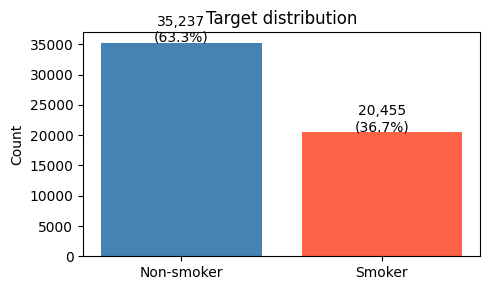

In [ ]:
class_counts = df["smoking"].value_counts()

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["Non-smoker", "Smoker"], class_counts.values, color=["steelblue", "tomato"])
ax.set_ylabel("Count")
ax.set_title("Target distribution")
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 200, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center")
plt.tight_layout()
plt.show()

### Smoking rate by gender

Gender turns out to be the single strongest predictor (correlation ≈ 0.51). Male smoking rates are dramatically higher than female, which we will revisit in our ablation experiment.

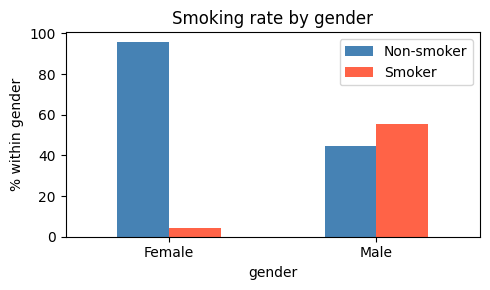

In [ ]:
gender_cross = pd.crosstab(df["gender"], df["smoking"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(5, 3))
gender_cross.plot(kind="bar", ax=ax, color=["steelblue", "tomato"], rot=0)
ax.set_xticklabels(["Female", "Male"])
ax.set_ylabel("% within gender")
ax.set_title("Smoking rate by gender")
ax.legend(["Non-smoker", "Smoker"])
plt.tight_layout()
plt.show()

### Distributions of key numeric features

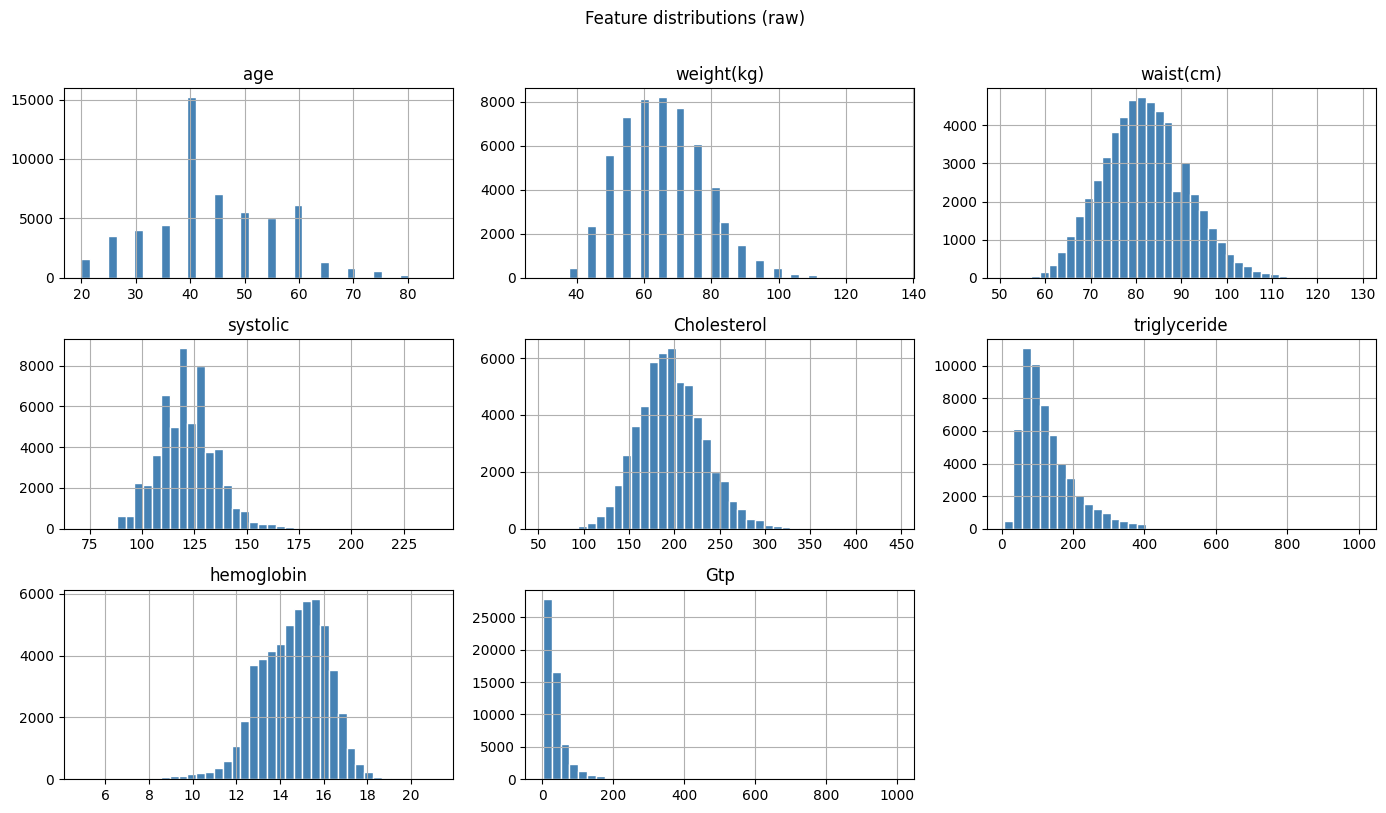

In [ ]:
numeric_cols = [
    "age", "weight(kg)", "waist(cm)", "systolic",
    "Cholesterol", "triglyceride", "hemoglobin", "Gtp","ALT"
]

df[numeric_cols].hist(figsize=(14, 8), bins=40, edgecolor="white", color="steelblue")
plt.suptitle("Feature distributions (raw)", y=1.01)
plt.tight_layout()
plt.show()

Triglyceride, GTP, and ALT are heavily right-skewed with extreme outliers. RobustScaler (used later) handles this without hard-capping values, which is preferable here since the extreme readings may genuinely indicate smoking-related liver stress.

### Outlier overview — boxplots

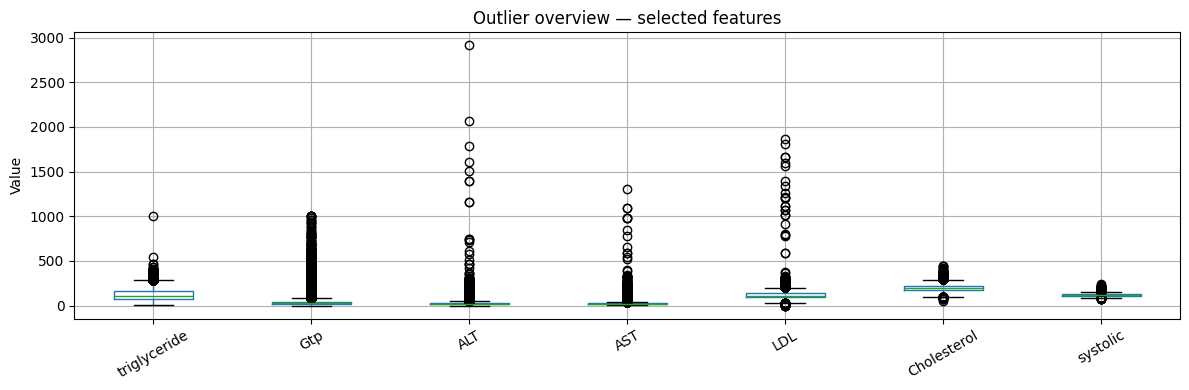

In [ ]:
outlier_cols = ["triglyceride", "Gtp", "ALT", "AST", "LDL", "Cholesterol", "systolic"]

fig, ax = plt.subplots(figsize=(12, 4))
df[outlier_cols].boxplot(ax=ax)
ax.set_title("Outlier overview — selected features")
ax.set_ylabel("Value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Smoker vs. non-smoker: mean differences

Rather than plotting individual boxplots for each feature, a quick mean difference table shows which features discriminate best.

In [ ]:
means = df.groupby("smoking")[numeric_cols].mean().T
means.columns = ["Non-smoker", "Smoker"]
means["Difference (%)"] = ((means["Smoker"] - means["Non-smoker"]) / means["Non-smoker"] * 100).round(1)
means.sort_values("Difference (%)", ascending=False)

,Non-smoker,Smoker,Difference (%)
Gtp,30.885859,55.570423,79.9
triglyceride,112.921957,150.341481,33.1
weight(kg),62.907455,70.959668,12.8
hemoglobin,14.144990,15.445339,9.2
waist(cm),80.447669,84.800518,5.4
systolic,120.732440,122.806502,1.7
Cholesterol,197.690921,195.541384,-1.1
age,45.677981,41.607431,-8.9


### Correlation with target

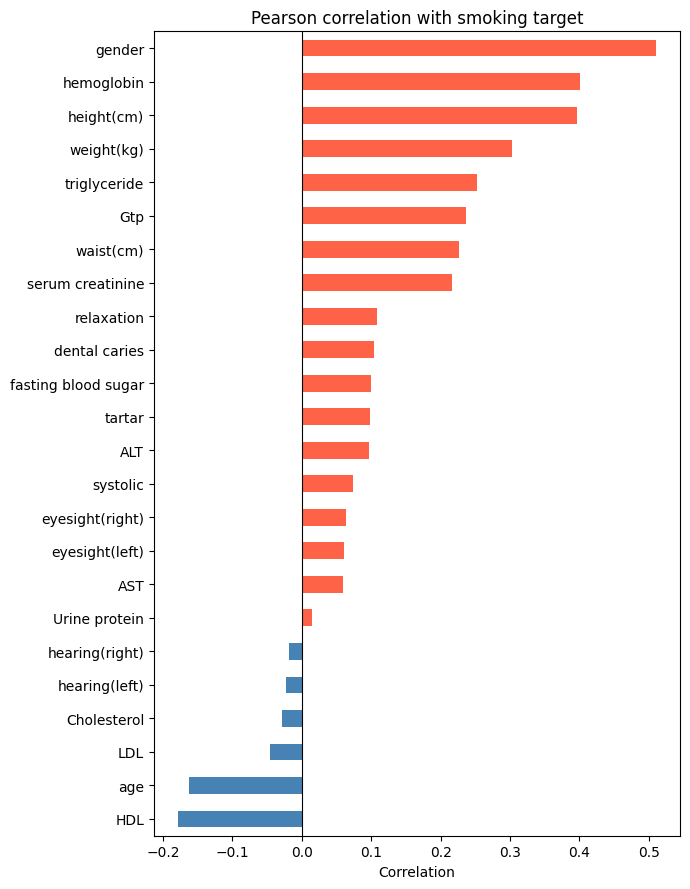

In [ ]:
# Encode gender temporarily just for the correlation plot
_tmp = df.copy()
_tmp["gender"] = _tmp["gender"].map({"F": 0, "M": 1})
_tmp["tartar"] = _tmp["tartar"].map({"N": 0, "Y": 1})

corr = _tmp.drop(columns=["ID", "oral"]).corr(numeric_only=True)["smoking"].drop("smoking").sort_values()

fig, ax = plt.subplots(figsize=(7, 9))
colors = ["tomato" if v > 0 else "steelblue" for v in corr]
corr.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Pearson correlation with smoking target")
ax.set_xlabel("Correlation")
plt.tight_layout()
plt.show()

del _tmp

### Full correlation matrix

The heatmap below shows pairwise Pearson correlations across all numeric features. Strongly correlated feature pairs (e.g. height/weight, systolic/relaxation, eyesight_left/right) justify our feature engineering choices therfore keeping both members of each pair would introduce near perfect multicollinearity.

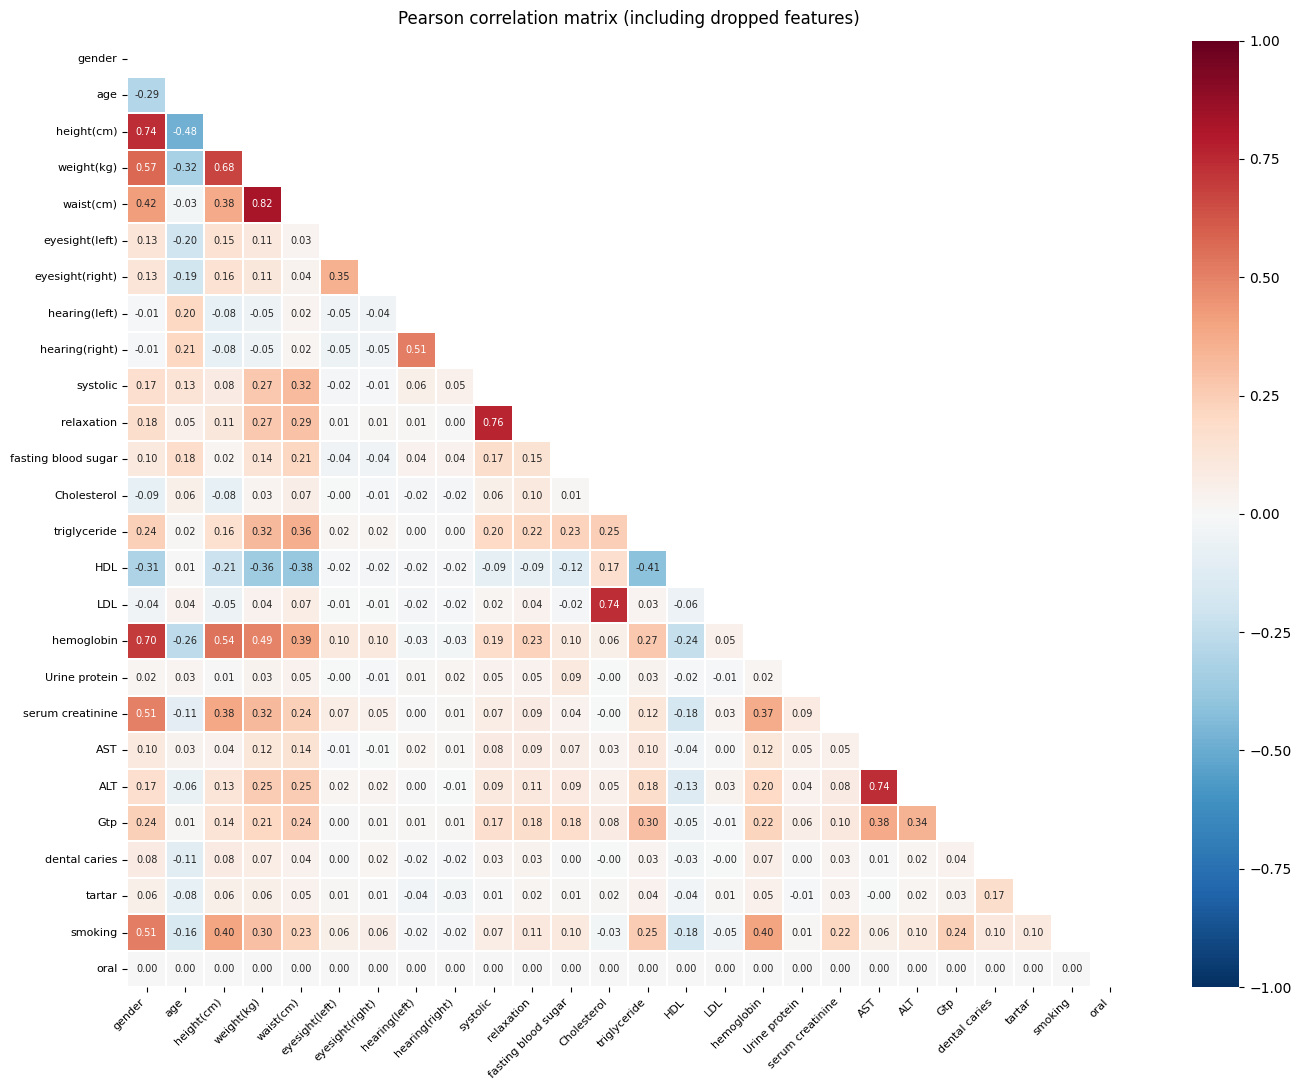

In [ ]:
# Prepare data
_tmp = df.copy()
if "gender" in _tmp.columns:
    _tmp["gender"] = _tmp["gender"].map({"F": 0, "M": 1})
if "tartar" in _tmp.columns:
    _tmp["tartar"] = _tmp["tartar"].map({"N": 0, "Y": 1})

# errors='ignore' prevents the crash if ID is already gone
# We don't drop 'oral' here so it can show up in the matrix
corr_matrix = _tmp.drop(columns=["ID"], errors='ignore').corr(numeric_only=True)

# If 'oral' is constant
# we put 0 as there is no variance
if "oral" not in corr_matrix.columns:
    corr_matrix["oral"] = 0.0
    corr_matrix.loc["oral"] = 0.0

# Plotting
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Simplified mask

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.3,
    ax=ax,
    annot_kws={"size": 7},
    vmin=-1, vmax=1,
)
ax.set_title("Pearson correlation matrix (including dropped features)", pad=12)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

del _tmp

The feature oral was identified as a constant feature (zero variance). Since it provides no information gain and has a mathematical correlation of 0 with the target, it was visualized here for completeness but will be excluded from model training.

## 4. Preprocessing & feature engineering

In [ ]:
# Clean column names so downstream code is less error-prone
df = df.rename(columns={
    "height(cm)": "height_cm",
    "weight(kg)": "weight_kg",
    "waist(cm)": "waist_cm",
    "eyesight(left)": "eyesight_left",
    "eyesight(right)": "eyesight_right",
    "hearing(left)": "hearing_left",
    "hearing(right)": "hearing_right",
    "fasting blood sugar": "fasting_blood_sugar",
    "Urine protein": "urine_protein",
    "serum creatinine": "serum_creatinine",
    "dental caries": "dental_caries",
})

# ID is an arbitrary row index; oral has ~0 correlation and very low variance
df = df.drop(columns=["ID", "oral"])

# Encode binary categoricals
df = df.rename(columns={"gender": "male"})
df["male"] = df["male"].map({"F": 0, "M": 1})
df["tartar"] = df["tartar"].map({"N": 0, "Y": 1})

### Feature engineering

Four composite features — each motivated by domain knowledge:

| Feature | Formula | Rationale |
|---|---|---|
| `BMI` | weight / height² | Widely used obesity indicator; replaces raw height + weight |
| `pulse_pressure` | systolic − relaxation | Arterial stiffness marker linked to cardiovascular risk |
| `avg_eyesight` | mean(left, right) | Single summary statistic; individual eyes add little extra signal |
| `hearing_problem` | 1 if either ear > 1 | Binary flag; the raw scale carries no meaningful ordinal info |

In [ ]:
df["BMI"] = df["weight_kg"] / (df["height_cm"] / 100) ** 2
df["pulse_pressure"] = df["systolic"] - df["relaxation"]
df["avg_eyesight"] = (df["eyesight_left"] + df["eyesight_right"]) / 2
df["hearing_problem"] = ((df["hearing_left"] > 1) | (df["hearing_right"] > 1)).astype(int)

df[["BMI", "pulse_pressure", "avg_eyesight", "hearing_problem"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,55692.0,24.17,3.48,14.27,21.6,23.88,26.12,42.45
pulse_pressure,55692.0,45.49,8.90,10.00,40.0,45.00,50.00,117.00
avg_eyesight,55692.0,1.01,0.40,0.10,0.8,1.00,1.20,9.90
hearing_problem,55692.0,0.04,0.19,0.00,0.0,0.00,0.00,1.00


### Column selection

With the composite features in place, the originals become redundant:
- `height_cm` + `weight_kg` → captured by `BMI`
- `systolic` + `relaxation` → captured by `pulse_pressure`
- `eyesight_left` + `eyesight_right` → captured by `avg_eyesight`
- `hearing_left` + `hearing_right` → captured by `hearing_problem`

Keeping them alongside the composites would introduce perfect multicollinearity (especially problematic for Logistic Regression).

In [ ]:
cols_to_drop = [
    "height_cm", "weight_kg",
    "systolic", "relaxation",
    "eyesight_left", "eyesight_right",
    "hearing_left", "hearing_right",
]

X = df.drop(columns=["smoking"] + cols_to_drop)
y = df["smoking"]

print(f"Feature matrix: {X.shape}")
print(X.columns.tolist())

Feature matrix: (55692, 20)
['male', 'age', 'waist_cm', 'fasting_blood_sugar', 'Cholesterol', 'triglyceride', 'HDL', 'LDL', 'hemoglobin', 'urine_protein', 'serum_creatinine', 'AST', 'ALT', 'Gtp', 'dental_caries', 'tartar', 'BMI', 'pulse_pressure', 'avg_eyesight', 'hearing_problem']


## 5. Train / test split & scaling

80/20 stratified split keeps the class ratio intact in both sets. The test set is held out completely until final evaluation — no peeking during hyperparameter search.

Scaling uses `RobustScaler` (median + IQR) which is appropriate here because several features (GTP, triglyceride) have heavy tails that would skew a standard z-score scaler.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scaler = RobustScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train smoker %: {y_train.mean()*100:.1f}%  |  Test smoker %: {y_test.mean()*100:.1f}%")

Train: (44553, 20)  |  Test: (11139, 20)
Train smoker %: 36.7%  |  Test smoker %: 36.7%


### Helper functions

Defined once here, called throughout the rest of the notebook.

In [ ]:
def print_metrics(name, y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"{'='*45}")
    print(f"  ROC-AUC   {roc_auc_score(y_true, y_prob):.4f}")
    print(f"  F1        {f1_score(y_true, y_pred):.4f}")
    print(f"  Precision {precision_score(y_true, y_pred):.4f}")
    print(f"  Recall    {recall_score(y_true, y_pred):.4f}")
    print(f"  Accuracy  {accuracy_score(y_true, y_pred):.4f}")
    print(f"  TN={tn}  FP={fp}  FN={fn}  TP={tp}")


def plot_cm_roc(model, X_t, y_true, y_pred, title_prefix, scaled=True):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred),
        display_labels=["Non-Smoker", "Smoker"],
    ).plot(ax=axes[0], colorbar=False)
    axes[0].set_title(f"{title_prefix} — Confusion Matrix")

    RocCurveDisplay.from_estimator(model, X_t, y_true, ax=axes[1], name=title_prefix)
    axes[1].plot([0, 1], [0, 1], "k--", label="Random")
    axes[1].set_title(f"{title_prefix} — ROC Curve")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 6. Baseline: Logistic Regression

LR is our interpretable baseline. `class_weight='balanced'` compensates for the 64/36 class split automatically.

In [ ]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)

lr_cv = cross_validate(
    lr, X_train_sc, y_train,
    cv=cv,
    scoring=["roc_auc", "f1", "accuracy"],
    n_jobs=-1,
)

print("Logistic Regression — 5-fold CV (train set)")
for metric in ["roc_auc", "f1", "accuracy"]:
    vals = lr_cv[f"test_{metric}"]
    print(f"  {metric:10s}  {vals.mean():.4f} ± {vals.std():.4f}")

Logistic Regression — 5-fold CV (train set)
  roc_auc     0.8299 ± 0.0035
  f1          0.7064 ± 0.0033
  accuracy    0.7196 ± 0.0034



  Logistic Regression
  ROC-AUC   0.8276
  F1        0.7054
  Precision 0.5741
  Recall    0.9147
  Accuracy  0.7195
  TN=4272  FP=2776  FN=349  TP=3742


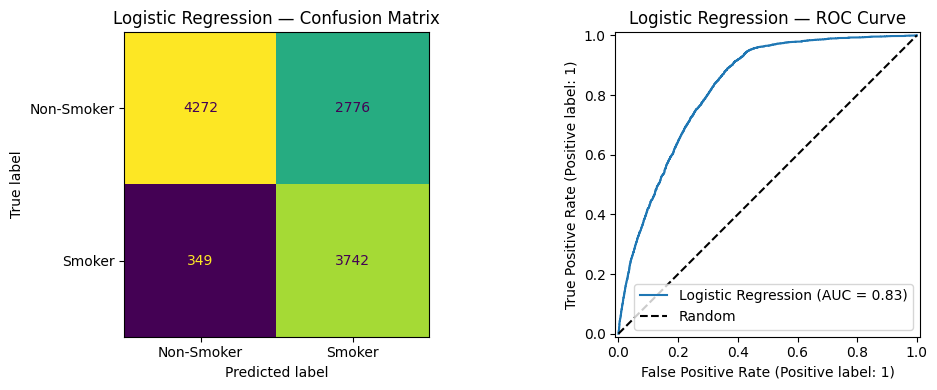

In [ ]:
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
y_prob_lr = lr.predict_proba(X_test_sc)[:, 1]

print_metrics("Logistic Regression", y_test, y_pred_lr, y_prob_lr)
plot_cm_roc(lr, X_test_sc, y_test, y_pred_lr, "Logistic Regression")

### Feature coefficients

Coefficient magnitude tells us how much each feature pushes the log-odds toward smoking.

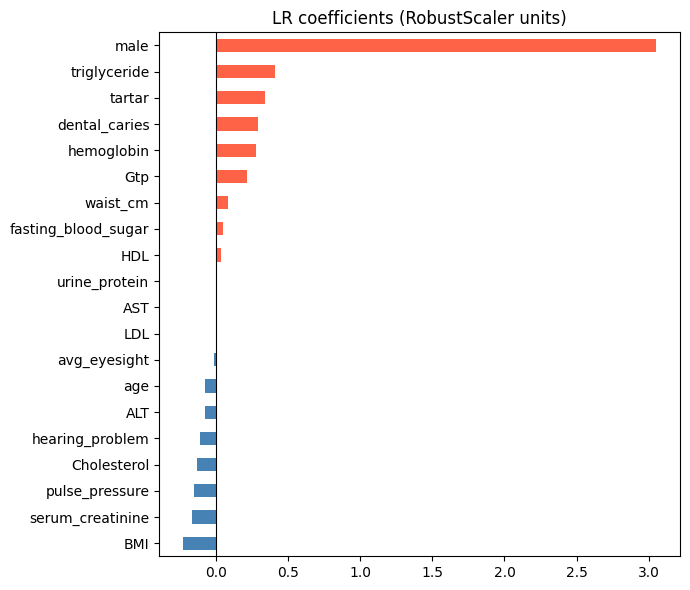

In [ ]:
coef = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["tomato" if v > 0 else "steelblue" for v in coef]
coef.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("LR coefficients (RobustScaler units)")
plt.tight_layout()
plt.show()

## 7. XGBoost: RandomizedSearch tuning

XGBoost is our primary non-symbolic model. `scale_pos_weight` replaces `class_weight` for gradient boosters — it reweights the positive class by the negative/positive ratio.

In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

param_dist_xgb = {
    "n_estimators":     [100, 200, 300, 400],
    "max_depth":        [3, 4, 5, 6],
    "learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "subsample":        [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric="logloss",
        verbosity=0,
    ),
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring="roc_auc",
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
)

xgb_search.fit(X_train, y_train)  # tree-based: no scaling needed

print("Best params:", xgb_search.best_params_)
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")

NameError: name 'y_train' is not defined


  XGBoost (tuned)
  ROC-AUC   0.8734
  F1        0.7425
  Precision 0.6776
  Recall    0.8213
  Accuracy  0.7908
  TN=5449  FP=1599  FN=731  TP=3360


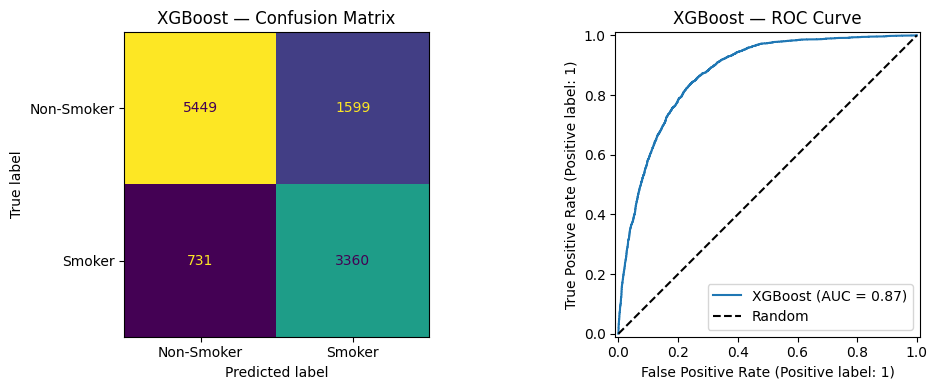

In [ ]:
xgb_best = xgb_search.best_estimator_
y_pred_xgb = xgb_best.predict(X_test)
y_prob_xgb = xgb_best.predict_proba(X_test)[:, 1]

print_metrics("XGBoost (tuned)", y_test, y_pred_xgb, y_prob_xgb)
plot_cm_roc(xgb_best, X_test, y_test, y_pred_xgb, "XGBoost")

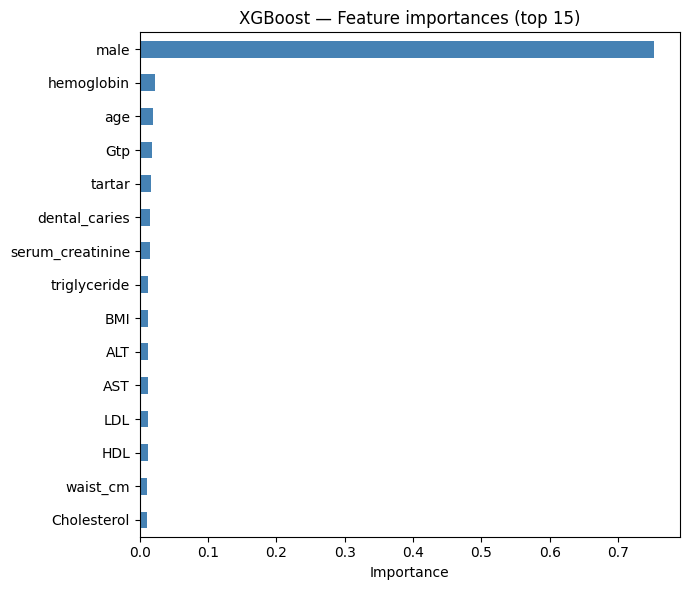

In [ ]:
feat_imp = pd.Series(xgb_best.feature_importances_, index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
feat_imp.tail(15).plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("XGBoost — Feature importances (top 15)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Random Forest: RandomizedSearch tuning

In [ ]:
param_dist_rf = {
    "n_estimators":      [100, 200, 300],
    "max_depth":         [5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [2, 4],
    "max_features":      ["sqrt", "log2"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1),
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
)

rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15}
Best CV ROC-AUC: 0.8798



  Random Forest (tuned)
  ROC-AUC   0.8854
  F1        0.7497
  Precision 0.6522
  Recall    0.8814
  Accuracy  0.7838
  TN=5125  FP=1923  FN=485  TP=3606


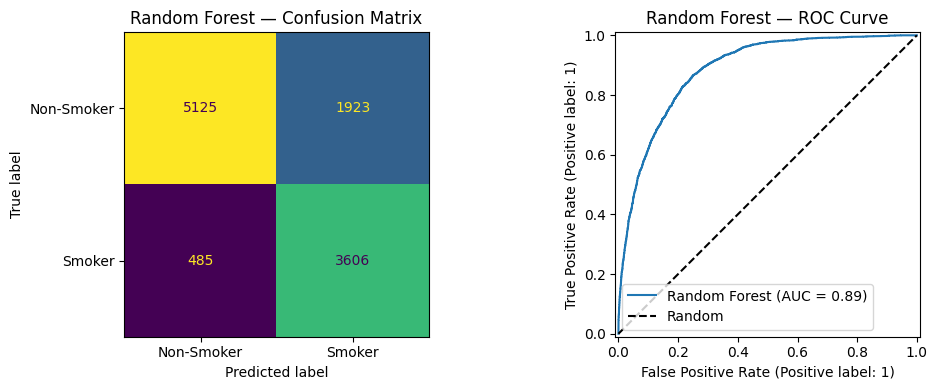

In [ ]:
rf_best = rf_search.best_estimator_
y_pred_rf = rf_best.predict(X_test)
y_prob_rf = rf_best.predict_proba(X_test)[:, 1]

print_metrics("Random Forest (tuned)", y_test, y_pred_rf, y_prob_rf)
plot_cm_roc(rf_best, X_test, y_test, y_pred_rf, "Random Forest")

## 9. Naïve Bayes: GridSearch tuning

Naïve Bayes was used as an additional probabilistic classification model. The only meaningful hyperparameter is `var_smoothing`, so GridSearch over a log-scale grid is sufficient.

In [ ]:
nb_search = GridSearchCV(
    GaussianNB(),
    param_grid={"var_smoothing": np.logspace(0, -9, num=10)},
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)

nb_search.fit(X_train_sc, y_train)

print(f"Best var_smoothing: {nb_search.best_params_}")
print(f"Best CV ROC-AUC:    {nb_search.best_score_:.4f}")

Best var_smoothing: {'var_smoothing': np.float64(1e-09)}
Best CV ROC-AUC:    0.7971



  Naïve Bayes (tuned)
  ROC-AUC   0.7948
  F1        0.6635
  Precision 0.5803
  Recall    0.7744
  Accuracy  0.7115
  TN=4757  FP=2291  FN=923  TP=3168


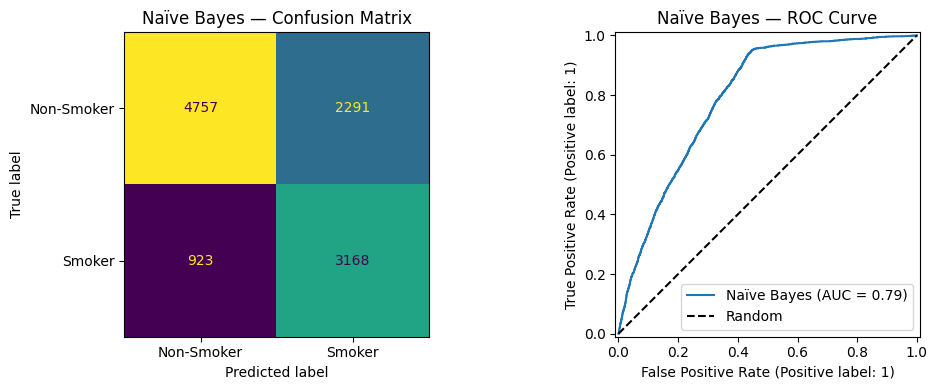

In [ ]:
nb_best = nb_search.best_estimator_
y_pred_nb = nb_best.predict(X_test_sc)
y_prob_nb = nb_best.predict_proba(X_test_sc)[:, 1]

print_metrics("Naïve Bayes (tuned)", y_test, y_pred_nb, y_prob_nb)
plot_cm_roc(nb_best, X_test_sc, y_test, y_pred_nb, "Naïve Bayes")

## 10. Ablation: removing the gender feature

Gender has a Pearson correlation of ~0.51 with by far the strongest single target predictor. In a real deployment, using gender as a model input raises fairness concerns: we would be systematically under-predicting smoking risk in men without gender data, and over-predicting in women. We therefore train all three models a second time without the `male` feature to see how much predictive power we actually lose, and whether the remaining biomarkers are sufficient.

Scaling is refit from scratch on the gender-dropped training data so that the scaler has no information about the removed column.

In [ ]:
X_train_ng = X_train.drop(columns=["male"])
X_test_ng = X_test.drop(columns=["male"])

# Refit scaler on gender-dropped training data
scaler_ng = RobustScaler()
X_train_ng_sc = scaler_ng.fit_transform(X_train_ng)
X_test_ng_sc = scaler_ng.transform(X_test_ng)

In [ ]:
# LR — no gender
lr_ng = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
lr_ng.fit(X_train_ng_sc, y_train)
y_pred_lr_ng = lr_ng.predict(X_test_ng_sc)
y_prob_lr_ng = lr_ng.predict_proba(X_test_ng_sc)[:, 1]
print_metrics("Logistic Regression (no gender)", y_test, y_pred_lr_ng, y_prob_lr_ng)


  Logistic Regression (no gender)
  ROC-AUC   0.7959
  F1        0.6639
  Precision 0.5868
  Recall    0.7644
  Accuracy  0.7158
  TN=4846  FP=2202  FN=964  TP=3127


In [ ]:
# XGBoost — no gender, reuse best hyperparams for fair comparison
xgb_ng = XGBClassifier(
    **xgb_search.best_params_,
    scale_pos_weight=scale_pos_weight,
    random_state=SEED,
    eval_metric="logloss",
    verbosity=0,
)
xgb_ng.fit(X_train_ng, y_train)
y_pred_xgb_ng = xgb_ng.predict(X_test_ng)
y_prob_xgb_ng = xgb_ng.predict_proba(X_test_ng)[:, 1]
print_metrics("XGBoost (no gender)", y_test, y_pred_xgb_ng, y_prob_xgb_ng)


  XGBoost (no gender)
  ROC-AUC   0.8615
  F1        0.7316
  Precision 0.6747
  Recall    0.7991
  Accuracy  0.7847
  TN=5472  FP=1576  FN=822  TP=3269


## feature importance after removing the gender for XGboost

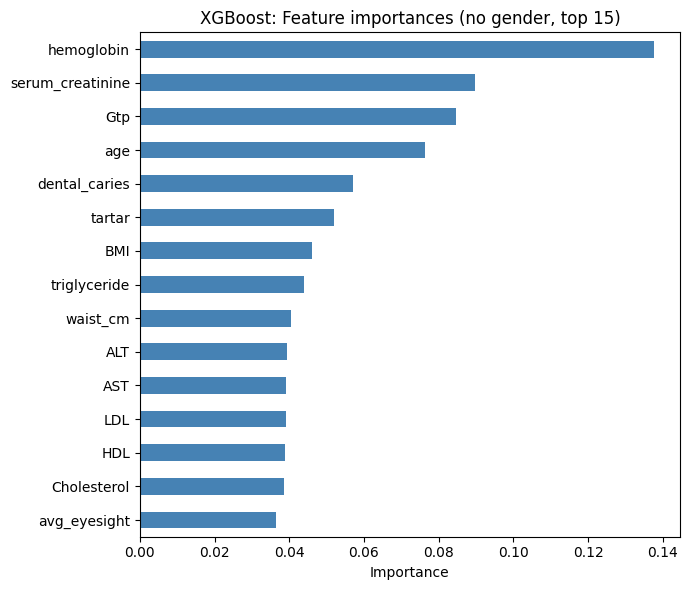

In [ ]:
# Create importance series using the 'no gender' model and columns
feat_imp_ng = pd.Series(xgb_ng.feature_importances_, index=X_train_ng.columns).sort_values()

# Optional: Add 'oral' back with 0 importance
if "oral" not in feat_imp_ng.index:
    feat_imp_ng["oral"] = 0.0
    feat_imp_ng = feat_imp_ng.sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
feat_imp_ng.tail(15).plot(kind="barh", ax=ax, color="steelblue")

ax.set_title("XGBoost: Feature importances (no gender, top 15)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
# Random Forest — no gender, reuse best hyperparams
rf_ng = RandomForestClassifier(
    **rf_search.best_params_,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
rf_ng.fit(X_train_ng, y_train)
y_pred_rf_ng = rf_ng.predict(X_test_ng)
y_prob_rf_ng = rf_ng.predict_proba(X_test_ng)[:, 1]
print_metrics("Random Forest (no gender)", y_test, y_pred_rf_ng, y_prob_rf_ng)


  Random Forest (no gender)
  ROC-AUC   0.8715
  F1        0.7340
  Precision 0.6707
  Recall    0.8106
  Accuracy  0.7843
  TN=5420  FP=1628  FN=775  TP=3316


In [ ]:
# Naïve Bayes — no gender (refit scaler already done above)
nb_ng_search = GridSearchCV(
    GaussianNB(),
    param_grid={"var_smoothing": np.logspace(0, -9, num=10)},
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)
nb_ng_search.fit(X_train_ng_sc, y_train)
nb_ng = nb_ng_search.best_estimator_
y_pred_nb_ng = nb_ng.predict(X_test_ng_sc)
y_prob_nb_ng = nb_ng.predict_proba(X_test_ng_sc)[:, 1]
print_metrics("Naïve Bayes (no gender)", y_test, y_pred_nb_ng, y_prob_nb_ng)


  Naïve Bayes (no gender)
  ROC-AUC   0.7651
  F1        0.5356
  Precision 0.6041
  Recall    0.4811
  Accuracy  0.6936
  TN=5758  FP=1290  FN=2123  TP=1968


## 11. Final comparison

In [ ]:
results = [
    ("Logistic Regression",       y_pred_lr,     y_prob_lr),
    ("Logistic Regression (–gender)", y_pred_lr_ng, y_prob_lr_ng),
    ("XGBoost",                   y_pred_xgb,    y_prob_xgb),
    ("XGBoost (–gender)",         y_pred_xgb_ng, y_prob_xgb_ng),
    ("Random Forest",             y_pred_rf,     y_prob_rf),
    ("Random Forest (–gender)",   y_pred_rf_ng,  y_prob_rf_ng),
    ("Naïve Bayes",               y_pred_nb,     y_prob_nb),
    ("Naïve Bayes (–gender)",     y_pred_nb_ng,  y_prob_nb_ng),
]

rows = []
for name, y_pred, y_prob in results:
    rows.append({
        "Model":     name,
        "ROC-AUC":   round(roc_auc_score(y_test, y_prob), 4),
        "F1":        round(f1_score(y_test, y_pred), 4),
        "Recall":    round(recall_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Accuracy":  round(accuracy_score(y_test, y_pred), 4),
    })

comparison = pd.DataFrame(rows).set_index("Model")
comparison.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,F1,Recall,Precision,Accuracy
Model,,,,,
Random Forest,0.8854,0.7497,0.8814,0.6522,0.7838
XGBoost,0.8734,0.7425,0.8213,0.6776,0.7908
Random Forest (–gender),0.8715,0.7340,0.8106,0.6707,0.7843
XGBoost (–gender),0.8615,0.7316,0.7991,0.6747,0.7847
Logistic Regression,0.8276,0.7054,0.9147,0.5741,0.7195
Logistic Regression (–gender),0.7959,0.6639,0.7644,0.5868,0.7158
Naïve Bayes,0.7948,0.6635,0.7744,0.5803,0.7115
Naïve Bayes (–gender),0.7651,0.5356,0.4811,0.6041,0.6936


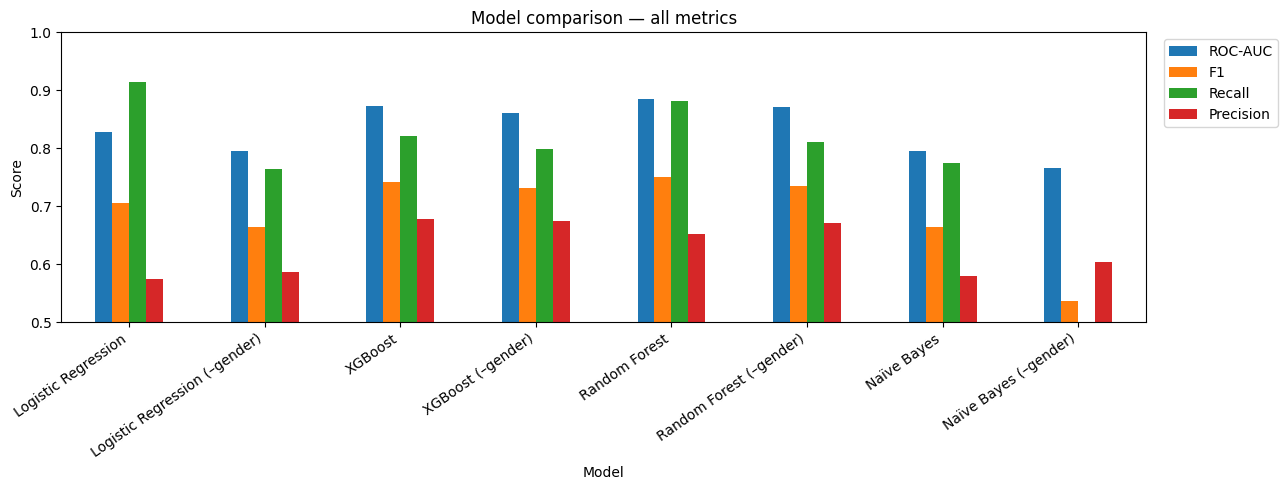

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
comparison[["ROC-AUC", "F1", "Recall", "Precision"]].plot(kind="bar", ax=ax)
ax.set_title("Model comparison — all metrics")
ax.set_ylabel("Score")
ax.set_ylim(0.5, 1.0)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Error analysis: best model

We look at the false negatives (smokers predicted as non-smokers) of our best model to understand where it still struggles.

In [ ]:
# Change the arrays below to whatever your best model is
best_pred = y_pred_xgb  # adjust if RF or another model wins
best_X_test = X_test

test_df = best_X_test.copy()
test_df["y_true"] = y_test.values
test_df["y_pred"] = best_pred

fn_df = test_df[(test_df["y_true"] == 1) & (test_df["y_pred"] == 0)]  # false negatives
tp_df = test_df[(test_df["y_true"] == 1) & (test_df["y_pred"] == 1)]  # true positives

print(f"False negatives (missed smokers): {len(fn_df)}")
print(f"True positives (caught smokers):  {len(tp_df)}")

numeric_feats = ["age", "waist_cm", "BMI", "Cholesterol", "triglyceride", "hemoglobin", "Gtp"]
compare = pd.DataFrame({
    "False Negatives (missed)": fn_df[numeric_feats].mean(),
    "True Positives (caught)": tp_df[numeric_feats].mean(),
})
compare["Δ"] = (compare["False Negatives (missed)"] - compare["True Positives (caught)"]).round(2)
compare.round(2)

False negatives (missed smokers): 731
True positives (caught smokers):  3360


,False Negatives (missed),True Positives (caught),Δ
age,42.89,41.46,1.43
waist_cm,83.22,85.29,-2.07
BMI,24.32,24.75,-0.43
Cholesterol,197.08,196.43,0.64
triglyceride,114.29,159.11,-44.81
hemoglobin,14.85,15.57,-0.73
Gtp,36.10,59.74,-23.64


## Summary

This project trained and evaluated four classifiers on the Body Signal of Smoking dataset
(55,692 records, 20 features after preprocessing) to predict smoking status from routine
health check-up data.

**Random Forest achieved the best performance** (ROC-AUC = 0.8854, F1 = 0.7497), narrowly
ahead of XGBoost (0.8734). Both ensemble methods substantially outperformed the symbolic
baselines Logistic Regression (0.8276) and Naïve Bayes (0.7948).

Gender (r = 0.51 with target) is the strongest single predictor in the dataset, but using
it as a model input is problematic in practice. A model that relies heavily on gender is
essentially saying "this person is likely a smoker because they are male", which is a
demographic shortcut rather than a medical finding. In a real screening tool this would
systematically over-flag men and under-flag women regardless of their actual biomarker
profile, which is both clinically misleading and ethically questionable. For this reason we
ran all models a second time without gender to assess whether the biomarker signal alone
is sufficient.

The answer is largely yes. Removing gender costs only ~0.014 AUC points for the ensemble
models (RF: 0.8854 → 0.8715, XGBoost: 0.8734 → 0.8615). Hemoglobin, GTP, and waist
circumference compensate for most of the lost signal. Naïve Bayes suffers more (recall
collapses from 0.77 to 0.48), suggesting it was leaning on gender more heavily than the
tree-based models.

Error analysis on the best model shows that missed smokers have significantly lower GTP
(36.1 vs 59.7 IU/L) and triglyceride (114.3 vs 159.1 mg/dL) than correctly identified
ones. Therefore, pointing to lighter or more recent smokers whose biochemistry has not yet diverged
from the non-smoker baseline as the hardest cases to classify.